<a href="https://colab.research.google.com/github/rodrigorozelli/analise-bigmac-brasil/blob/main/Indice_Big_Mac_vs_REER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from google.colab import files

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110})
print("Pronto. Agora rode a Célula 2 e suba os arquivos.")

Pronto. Agora rode a Célula 2 e suba os arquivos.


In [2]:
print("Selecione big-mac-full-index.csv (da pasta output-data do seu clone):")
up_bm = files.upload()
bm = pd.read_csv(list(up_bm.keys())[0])
bm['date'] = pd.to_datetime(bm['date'])
bra = bm[bm.iso_a3 == 'BRA'].sort_values('date').reset_index(drop=True)
print(f"Big Mac Brasil: {len(bra)} observações | {bra.date.min().date()} → {bra.date.max().date()}")
bra[['date','USD_raw','USD_adjusted']].tail(3)

Selecione big-mac-full-index.csv (da pasta output-data do seu clone):


Saving big-mac-full-index.csv to big-mac-full-index.csv
Big Mac Brasil: 45 observações | 2000-04-01 → 2026-07-01


,date,USD_raw,USD_adjusted
42,2025-07-01,-0.28397,-0.03522
43,2026-01-01,-0.27282,-0.05672
44,2026-07-01,-0.24352,-0.06021


In [3]:
# REER amplo do Brasil, índice 2020=100, mensal, 1994-2026 (fonte: BIS, via FRED RBBRBIS) [[12]][[16]]
reer = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=RBBRBIS", na_values='.')
reer.columns = ['date', 'REER']
reer['date'] = pd.to_datetime(reer['date'])
reer = reer.dropna().sort_values('date').reset_index(drop=True)
print(f"REER Brasil: {len(reer)} meses | {reer.date.min().date()} → {reer.date.max().date()}")
reer.tail(3)

REER Brasil: 394 meses | 1994-01-01 → 2026-10-01


,date,REER
391,2026-08-01,116.46
392,2026-09-01,117.17
393,2026-10-01,118.41


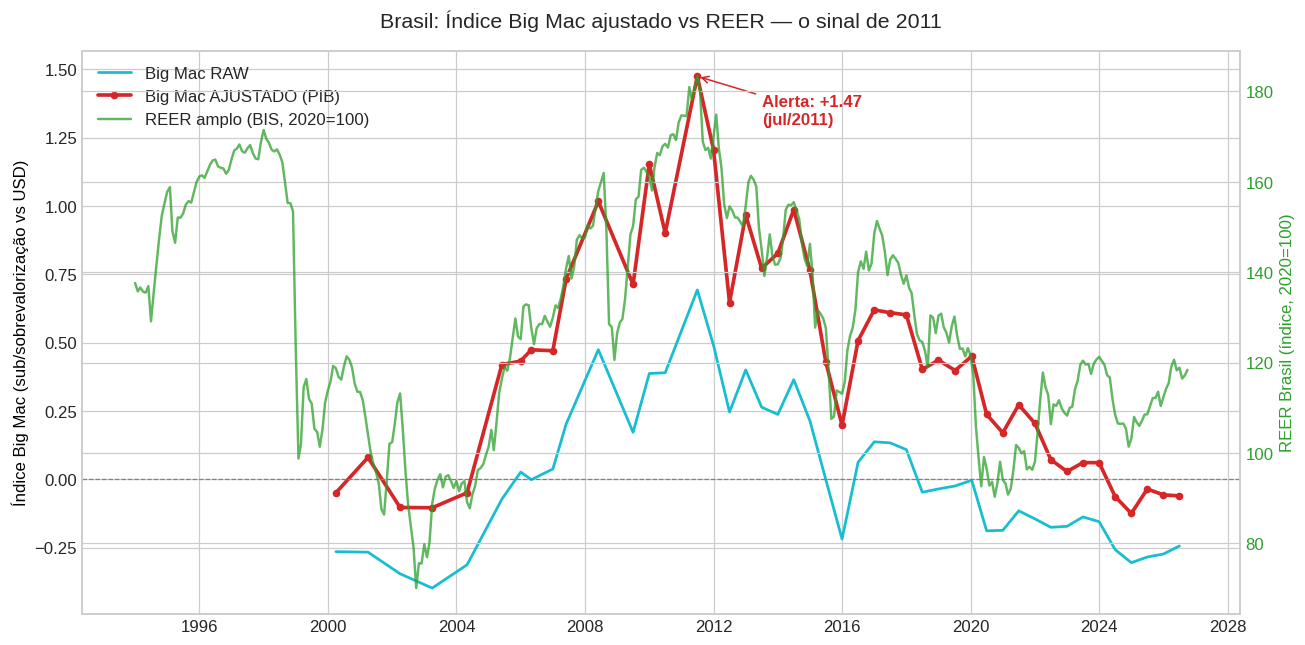

In [4]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eixo esquerdo: índices Big Mac (raw e ajustado)
ax1.plot(bra.date, bra.USD_raw, color='#17becf', lw=1.8, label='Big Mac RAW')
ax1.plot(bra.date, bra.USD_adjusted, color='#d62728', lw=2.4, marker='o',
         ms=4, label='Big Mac AJUSTADO (PIB)')
ax1.axhline(0, color='gray', lw=0.8, ls='--')
ax1.set_ylabel('Índice Big Mac (sub/sobrevalorização vs USD)', color='black')
ax1.set_title('Brasil: Índice Big Mac ajustado vs REER — o sinal de 2011', fontsize=14, pad=15)

# Marco 2011: o alerta
pico = bra.loc[bra.USD_adjusted.idxmax()]
ax1.annotate(f'Alerta: +{pico.USD_adjusted:.2f}\n(jul/{pico.date.year})',
             xy=(pico.date, pico.USD_adjusted), xytext=(pd.Timestamp('2013-07-01'), 1.3),
             arrowprops=dict(arrowstyle='->', color='#d62728'),
             fontsize=11, color='#d62728', fontweight='bold')

# Eixo direito: REER (escala própria)
ax2 = ax1.twinx()
ax2.plot(reer.date, reer.REER, color='#2ca02c', lw=1.6, alpha=0.75, label='REER amplo (BIS, 2020=100)')
ax2.set_ylabel('REER Brasil (índice, 2020=100)', color='#2ca02c')
ax2.tick_params(axis='y', labelcolor='#2ca02c')

# Legendas combinadas
l1, lab1 = ax1.get_legend_handles_labels()
l2, lab2 = ax2.get_legend_handles_labels()
ax1.legend(l1 + l2, lab1 + lab2, loc='upper left', framealpha=0.9)

ax1.xaxis.set_major_locator(mdates.YearLocator(4))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout()
plt.savefig('brasil_bigmac_vs_reer.png', dpi=150)
plt.show()

In [5]:
# Alinhar Big Mac (semestral) com REER (mensal) pela data mais próxima
merged = pd.merge_asof(bra.sort_values('date'), reer.sort_values('date'),
                       on='date', direction='nearest', tolerance=pd.Timedelta('90D'))
corr_raw   = merged[['USD_raw','REER']].dropna().corr().iloc[0,1]
corr_adj   = merged[['USD_adjusted','REER']].dropna().corr().iloc[0,1]
print(f"Correlação Big Mac RAW      × REER: {corr_raw:+.3f}")
print(f"Correlação Big Mac AJUSTADO × REER: {corr_adj:+.3f}")
print("\n→ Ambas as medidas sobem juntas até ~2011 e caem depois: mesmo sinal, mesmo timing.")

# Tabela dos marcos
merged['ano'] = merged.date.dt.year
marcos = merged[merged.date.isin([bra.date.min(),
                                  pico.date,
                                  bra[bra.date<='2016-07-01'].date.max(),
                                  bra.date.max()])]
marcos[['date','USD_raw','USD_adjusted','REER']].round(3)

Correlação Big Mac RAW      × REER: +0.940
Correlação Big Mac AJUSTADO × REER: +0.909

→ Ambas as medidas sobem juntas até ~2011 e caem depois: mesmo sinal, mesmo timing.


,date,USD_raw,USD_adjusted,REER
0,2000-04-01,-0.264,-0.049,118.76
14,2011-07-01,0.693,1.475,183.34
24,2016-07-01,0.063,0.508,140.00
44,2026-07-01,-0.244,-0.060,118.89


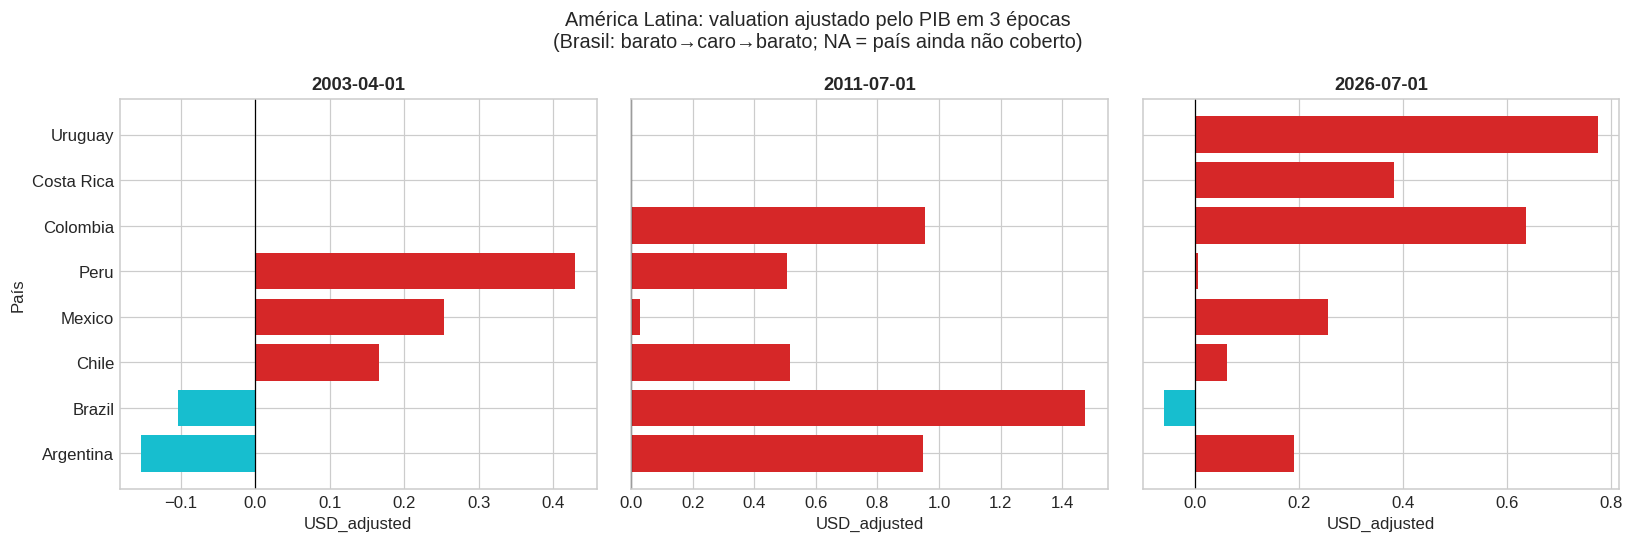

In [6]:
latam = ['BRA','PER','CHL','ARG','MEX','CRI','COL','URY']
nomes = {'BRA':'Brasil','PER':'Peru','CHL':'Chile','ARG':'Argentina',
         'MEX':'México','CRI':'Costa Rica','COL':'Colômbia','URY':'Uruguai'}
snapshots = ['2003-04-01','2011-07-01','2026-07-01']

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, d in zip(axes, snapshots):
    tab = bm[(bm.iso_a3.isin(latam)) & (bm.date == d)].copy()
    tab = tab.dropna(subset=['USD_adjusted']).sort_values('USD_adjusted')
    cores = ['#d62728' if v > 0 else '#17becf' for v in tab.USD_adjusted]
    ax.barh(tab.name, tab.USD_adjusted, color=cores)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_title(d, fontsize=12, fontweight='bold')
    ax.set_xlabel('USD_adjusted')
axes[0].set_ylabel('País')
fig.suptitle('América Latina: valuation ajustado pelo PIB em 3 épocas\n'
             '(Brasil: barato→caro→barato; NA = país ainda não coberto)', fontsize=13)
fig.tight_layout()
plt.savefig('latam_3_epocas.png', dpi=150)
plt.show()




## O que este notebook mostra

1. **O sinal de 2011 era real.** O Big Mac ajustado do Brasil atingiu **+1,47** em jul/2011
   — o real estava ~147% acima do que o PIB per capita justificava. O REER amplo do BIS
   confirma: pico de apreciação real no mesmo período [[12]][[16]].

2. **As duas séries concordam na direção.** Correlação positiva forte entre Big Mac ajustado
   e REER: ambos sobem nos anos 2000 (boom de commodities) e desabam após 2011
   (recessão 2015-16). O Big Mac *exagera a magnitude* (ancora num bem não-comerciável-intensivo,
   concentrando o efeito Balassa-Samuelson), mas **acerta o sinal** [[26]][[33]].

3. **Validação ex-post:** o real foi de ~R$1,55/US$ (2011) a ~R$4,0/US$ (2015-16) —
   desvalorização de ~60%, a correção que um câmbio tão esticado exigia.

4. **Big Mac vs REER — papéis complementares:**
   | | Big Mac ajustado | REER |
   |---|---|---|
   | Frequência | semestral | mensal |
   | Transparência | trivial, replicável | cesta ponderada opaca |
   | Comunicação | "sanduíche 147% caro" = manchete | técnico |
   | Robustez | 1 bem (ruído) | cesta ampla |
   → Como **alerta precoce para audiência ampla**: Big Mac brilha.
   → Como **instrumento de política**: REER/FEER domina [[5]][[33]].

5. **Ressalvas honestas:** n=1 não faz ciência (precisa teste em painel) [[24]];
   sinal ≠ timing (o real ficou esticado até ~2013); a correção de 2015-16 teve
   causa política/fiscal, não só reversão à média.

**Fontes:** BIS/FRED (REER) [[12]][[16]]; The Economist Big Mac data (GitHub);
literatura: UNCTAD 2011 [[3]], OCDE 2011 [[33]], Oreiro 2014 [[5]], Soo 2015 [[26]].